# PCA for gas sensor data

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/unsupervised-learning/01-pca-gas-sensor-array.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

In this notebook, we will build a **multiclass classification model** to identify a gas from the responses of a sensor array. Our data come from the [UCI Gas Sensor Array Drift dataset](https://archive.ics.uci.edu/dataset/224/gas+sensor+array+drift+dataset), which contains measurements of six gases collected using 16 metal-oxide sensors. Each gas exposure produces a set of readings from the sensors.

We will then use **principal component analysis (PCA)** to combine the sensor measurements into a smaller number of new features. We will compare a classifier using the leading principal components with one using all 16 sensor readings, and plot the data to see how PCA can help us explore this classification task.

The source data contain 128 features per gas exposure: eight summaries of the response from each of the 16 sensors, rather than the original sensor readings over time. We will inspect all 128, then use the steady-state resistance change (ΔR) from each sensor (16 values total). The full dataset includes measurements collected over multiple batches as the sensors aged; we will work with one batch.

## What we will do

1. Download and inspect one batch of the original UCI data.
2. Fit a random forest to classify the gases and use its feature importance scores to select two sensor readings.
3. Standardize the 16 steady-state sensor readings and fit PCA without using gas labels.
4. Compare random forest classifiers using all 16 sensor readings and the first 2, 3, or 4 PCs.
5. Plot the two selected sensor readings alongside the first two principal components.

Gas labels are used to fit the feature-ranking model and, later, to color plots and evaluate classifiers. **PCA itself never sees the labels.**

## 1. Download the data and inspect its raw format

The file is distributed in [LIBSVM text format](https://github.com/cjlin1/libsvm/blob/master/README). Each line starts with a numeric gas label and then lists feature-number/value pairs. UCI organizes the measurements into batches; here we take Batch 1 (445 samples) so the first example stays compact and does not mix in longer-term sensor drift across batches.

Each of the 16 sensors contributes eight response summaries: steady-state resistance change (ΔR), normalized ΔR, and six summaries of the rising and falling response. That gives 128 features per sample. We will first inspect the complete feature vector, then focus the model comparison on one measurement per sensor—the steady-state ΔR. The [UCI documentation](https://archive.ics.uci.edu/dataset/224/gas+sensor+array+drift+dataset) describes the feature layout, class labels, and batch structure.

In [1]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.datasets import load_svmlight_file
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Show DataFrame values to one decimal place; calculations keep full precision.
pd.options.display.float_format = "{:.1f}".format
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
RANDOM_STATE = 4520

GAS_NAMES = {
    1: "Ethanol",
    2: "Ethylene",
    3: "Ammonia",
    4: "Acetaldehyde",
    5: "Acetone",
    6: "Toluene",
}
GAS_ORDER = list(GAS_NAMES.values())
GAS_PALETTE = dict(zip(GAS_ORDER, sns.color_palette("colorblind", n_colors=6)))

In [2]:
# UCI provides this dataset as a ZIP archive of separate batch files, not a
# ready-to-read CSV; it is not currently available through ucimlrepo's loader.
# Download the archive into memory; nothing needs to be uploaded to Drive.
DATA_URL = (
    "https://archive.ics.uci.edu/static/public/224/"
    "gas%2Bsensor%2Barray%2Bdrift%2Bdataset.zip"
)

with urlopen(DATA_URL, timeout=60) as response:
    archive_bytes = response.read()

with ZipFile(BytesIO(archive_bytes)) as archive:
    # The archive includes ten time-ordered batch files.
    batch1_bytes = archive.read("Dataset/batch1.dat")

# Keep a decoded copy so we can inspect the original text line.
batch1_text = batch1_bytes.decode("utf-8")

# Batch files use LIBSVM format (a label followed by feature:value pairs),
# so use scikit-learn's parser instead of pandas.read_csv().
X_sparse, y = load_svmlight_file(BytesIO(batch1_bytes), n_features=128)
X_full = X_sparse.toarray()
y = y.astype(int)

print(f"Complete raw feature matrix: {X_full.shape[0]} samples × {X_full.shape[1]} features")

Complete raw feature matrix: 445 samples × 128 features


First, here is one line exactly as it appears in the downloaded file. To keep the display readable, we show only the beginning of the line.

In [3]:
print(batch1_text.splitlines()[0][:260] + " ...")

1 1:15596.162100 2:1.868245 3:2.371604 4:2.803678 5:7.512213 6:-2.739388 7:-3.344671 8:-4.847512 9:15326.691400 10:1.768526 11:2.269085 12:2.713374 13:6.915721 14:-2.488324 15:-3.082212 16:-5.056975 17:2789.383100 18:2.754759 19:0.430440 20:0.649457 21:1.79502 ...


We will give all 128 raw columns descriptive names based on the UCI feature ordering, and preview the complete table. Then we select each sensor's first measurement, ΔR, to form a 445 × 16 matrix for the comparison. This avoids letting the same sensor enter several times through multiple summaries of its response.

In [4]:
FEATURE_DESCRIPTORS = [
    "ΔR steady state",
    "normalized ΔR",
    "EMA rising α=0.001",
    "EMA rising α=0.01",
    "EMA rising α=0.1",
    "EMA falling α=0.001",
    "EMA falling α=0.01",
    "EMA falling α=0.1",
]

ALL_FEATURE_NAMES = [
    f"Sensor {sensor:02d} — {descriptor}"
    for sensor in range(1, 17)
    for descriptor in FEATURE_DESCRIPTORS
]

raw_data = pd.DataFrame(X_full, columns=ALL_FEATURE_NAMES)
raw_data.insert(0, "gas", pd.Series(y).map(GAS_NAMES).to_numpy())
raw_data.insert(0, "gas_code", y)

# The first of each sensor's eight features is its steady-state ΔR response.
STEADY_STATE_INDICES = np.arange(0, 128, 8)
FEATURE_NAMES = [ALL_FEATURE_NAMES[index] for index in STEADY_STATE_INDICES]
X = X_full[:, STEADY_STATE_INDICES]
data = pd.DataFrame(X, columns=FEATURE_NAMES)
data.insert(0, "gas", pd.Series(y).map(GAS_NAMES).to_numpy())
data.insert(0, "gas_code", y)

print("Complete raw table (all 128 feature columns; pandas abbreviates the middle columns):")
display(raw_data.head())
print("Analysis table: first two rows per gas, with their original indices:")
display(data.groupby("gas", sort=False).head(2))

Complete raw table (all 128 feature columns; pandas abbreviates the middle columns):


,gas_code,gas,Sensor 01 — ΔR steady state,Sensor 01 — normalized ΔR,Sensor 01 — EMA rising α=0.001,Sensor 01 — EMA rising α=0.01,Sensor 01 — EMA rising α=0.1,Sensor 01 — EMA falling α=0.001,Sensor 01 — EMA falling α=0.01,Sensor 01 — EMA falling α=0.1,...,Sensor 15 — EMA falling α=0.01,Sensor 15 — EMA falling α=0.1,Sensor 16 — ΔR steady state,Sensor 16 — normalized ΔR,Sensor 16 — EMA rising α=0.001,Sensor 16 — EMA rising α=0.01,Sensor 16 — EMA rising α=0.1,Sensor 16 — EMA falling α=0.001,Sensor 16 — EMA falling α=0.01,Sensor 16 — EMA falling α=0.1
0,1,Ethanol,15596.2,1.9,2.4,2.8,7.5,-2.7,-3.3,-4.8,...,-1.1,-3.0,3037.0,4.0,0.5,0.7,1.4,-0.5,-0.9,-2.7
1,1,Ethanol,26402.1,2.5,5.4,6.5,7.7,-4.7,-5.8,-7.5,...,-1.5,-2.0,4176.4,4.3,1.0,1.6,2.0,-0.9,-1.3,-1.7
2,1,Ethanol,42103.6,3.5,8.2,10.5,11.6,-7.7,-9.5,-12.2,...,-2.4,-2.9,5914.7,5.4,1.4,2.5,3.0,-1.3,-2.0,-2.3
3,1,Ethanol,42826.0,3.5,12.1,16.3,39.9,-7.8,-9.7,-11.9,...,-2.6,-3.1,6147.5,5.5,2.0,3.6,4.0,-1.4,-2.1,-2.5
4,1,Ethanol,58151.2,4.2,11.5,15.7,17.7,-11.1,-13.6,-16.4,...,-3.6,-4.2,8158.6,7.2,2.0,3.8,4.4,-1.9,-2.9,-4.1


Analysis table: first two rows per gas, with their original indices:


,gas_code,gas,Sensor 01 — ΔR steady state,Sensor 02 — ΔR steady state,Sensor 03 — ΔR steady state,Sensor 04 — ΔR steady state,Sensor 05 — ΔR steady state,Sensor 06 — ΔR steady state,Sensor 07 — ΔR steady state,Sensor 08 — ΔR steady state,Sensor 09 — ΔR steady state,Sensor 10 — ΔR steady state,Sensor 11 — ΔR steady state,Sensor 12 — ΔR steady state,Sensor 13 — ΔR steady state,Sensor 14 — ΔR steady state,Sensor 15 — ΔR steady state,Sensor 16 — ΔR steady state
0,1,Ethanol,15596.2,15326.7,2789.4,2581.6,685.4,797.8,3128.8,3136.9,13540.7,13831.8,3020.9,2186.0,862.7,1059.8,3357.1,3037.0
1,1,Ethanol,26402.1,23855.8,3882.9,3651.0,982.9,1162.2,4332.2,4387.5,20553.6,22540.2,4240.3,3079.1,1237.0,1459.6,4685.8,4176.4
84,2,Ethylene,3115.2,3141.8,4323.2,4045.2,646.9,745.6,4243.2,4272.6,3014.0,2685.9,4388.0,2825.1,728.6,908.9,4717.9,3968.8
85,2,Ethylene,9056.4,8520.2,13104.1,12184.7,1990.3,2260.7,12715.4,12909.4,8627.6,7412.7,13152.0,8541.5,2173.2,2640.7,14286.2,11744.6
172,3,Ammonia,7858.2,2802.3,11827.9,13037.3,1995.9,2234.2,10000.5,10928.5,4823.7,3813.7,13508.0,9988.2,2135.1,2362.5,12262.7,10294.7
173,3,Ammonia,4860.7,4228.7,11285.5,13541.3,2757.0,3127.2,9727.7,10934.3,6422.3,5093.0,14377.5,13441.2,2941.1,3259.6,12986.1,11174.3
271,4,Acetaldehyde,53217.9,53349.3,2768.0,2619.8,918.3,1045.6,3360.7,3388.8,48892.5,49252.7,3103.6,2280.1,1173.0,1275.1,3779.1,3359.4
272,4,Acetaldehyde,90773.0,86650.2,4129.7,3864.4,1311.4,1472.6,4941.9,4947.1,79365.4,80227.9,4529.4,3367.1,1595.3,1774.5,5472.5,4878.2
301,5,Acetone,101302.8,93237.3,2691.7,2529.3,874.9,992.5,3294.7,3294.5,84523.1,87446.4,3054.1,2223.0,1107.1,1171.2,3759.4,3348.9
302,5,Acetone,162506.8,147073.8,4726.6,4332.1,1424.6,1588.0,5700.4,5603.7,133759.1,136987.5,5191.9,3899.2,1734.5,1877.5,6413.7,5762.3


## 2. Basic exploratory data analysis

Each row is one gas exposure. The complete raw table has eight response summaries for each of 16 sensors; the analysis table keeps one steady-state ΔR value per sensor. The original UCI file version used here does not include a concentration column. Its labels identify which gas was tested.

First, check how many observations we have for each gas.

,observations
gas,
Ethanol,90
Ethylene,98
Ammonia,83
Acetaldehyde,30
Acetone,70
Toluene,74


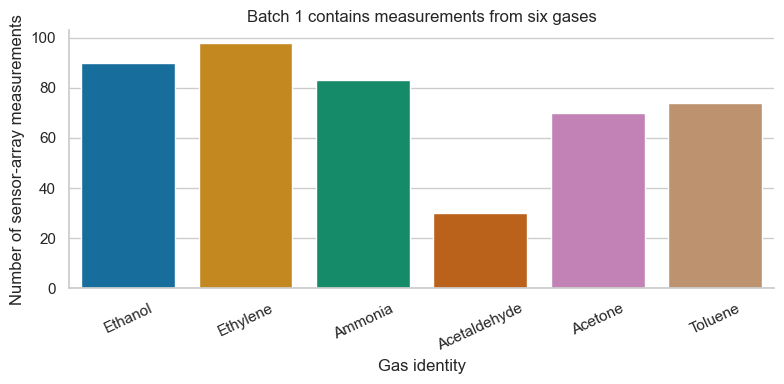

In [5]:
class_counts = (
    data["gas"]
    .value_counts()
    .reindex(GAS_ORDER)
    .rename("observations")
    .to_frame()
)
display(class_counts)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    x=class_counts.index,
    y=class_counts["observations"],
    hue=class_counts.index,
    palette=GAS_PALETTE,
    legend=False,
    ax=ax,
)
ax.set(
    title="Batch 1 contains measurements from six gases",
    xlabel="Gas identity",
    ylabel="Number of sensor-array measurements",
)
ax.tick_params(axis="x", rotation=25)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

In [6]:
# Summarize the steady-state ΔR readings for the first eight sensors.
# Sensor responses have very different scales, so standardization matters.
sensor_summary = data[FEATURE_NAMES[:8]].describe().T[
    ["min", "50%", "mean", "std", "max"]
]
display(sensor_summary.rename(columns={"50%": "median"}))

print(f"Missing feature values: {data[FEATURE_NAMES].isna().sum().sum()}")

,min,median,mean,std,max
Sensor 01 — ΔR steady state,-518.4,73888.5,125598.2,154508.3,670687.3
Sensor 02 — ΔR steady state,-40.1,69638.9,107079.6,121832.0,502202.8
Sensor 03 — ΔR steady state,185.4,13941.1,15899.6,10649.3,46951.2
Sensor 04 — ΔR steady state,166.7,14520.8,15560.0,10040.6,42158.9
Sensor 05 — ΔR steady state,0.6,3376.6,3920.8,2580.7,11857.4
Sensor 06 — ΔR steady state,3.3,3801.7,4471.0,2994.3,13800.2
Sensor 07 — ΔR steady state,112.5,13491.3,16272.6,10756.1,56038.4
Sensor 08 — ΔR steady state,114.6,14356.2,16686.2,10815.8,54877.9


Missing feature values: 0


## 3. Hold out data before ranking features or fitting PCA

We will use a stratified 70/30 train/test split. Stratification preserves each gas's approximate share in both sets. We fit the random forest, scalers, PCA, and classifiers using the training data only; the test data is held back until evaluation.

In [7]:
train_idx, test_idx = train_test_split(
    np.arange(len(y)),
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y,
)

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

train_counts = pd.Series(y_train).value_counts().reindex(GAS_NAMES)
test_counts = pd.Series(y_test).value_counts().reindex(GAS_NAMES)
split_summary = pd.DataFrame(
    {
        "training samples": train_counts.to_numpy(),
        "test samples": test_counts.to_numpy(),
    },
    index=GAS_ORDER,
)
display(split_summary)
print(f"Training: {len(train_idx)} rows; test: {len(test_idx)} rows")

,training samples,test samples
Ethanol,63,27
Ethylene,68,30
Ammonia,58,25
Acetaldehyde,21,9
Acetone,49,21
Toluene,52,22


Training: 311 rows; test: 134 rows


## 4. Which two sensor readings look most informative?

We first fit a random forest to predict the gas from the 16 sensor readings. Its feature importance scores tell us how much each reading contributed to reducing impurity across the trees. We use these scores to select two readings for our plots and model comparison.

Training the random forest uses the gas labels, so this is a supervised learning task.

In [8]:
forest_options = {
    "n_estimators": 500,
    "max_features": "sqrt",
    "min_samples_leaf": 2,
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
}
feature_ranker = RandomForestClassifier(**forest_options)
feature_ranker.fit(X_train, y_train)

importance = pd.DataFrame(
    {
        "source_feature_number": STEADY_STATE_INDICES + 1,
        "sensor": np.arange(1, X.shape[1] + 1),
        "feature": FEATURE_NAMES,
        "importance": feature_ranker.feature_importances_,
    }
).sort_values("importance", ascending=False, ignore_index=True)

top_two_features = importance.loc[:1, "feature"].tolist()
top_two_indices = [FEATURE_NAMES.index(name) for name in top_two_features]

importance_display = importance.head(10).copy()
importance_display["importance"] = importance_display["importance"].map("{:.1%}".format)
display(importance_display)
print("Selected raw features:")
for row in importance.head(2).itertuples(index=False):
    print(f"  Sensor {row.sensor} (raw feature {row.source_feature_number}): {row.feature}")

,source_feature_number,sensor,feature,importance
0,9,2,Sensor 02 — ΔR steady state,15.2%
1,1,1,Sensor 01 — ΔR steady state,14.0%
2,65,9,Sensor 09 — ΔR steady state,10.2%
3,73,10,Sensor 10 — ΔR steady state,10.1%
4,41,6,Sensor 06 — ΔR steady state,6.8%
5,17,3,Sensor 03 — ΔR steady state,5.9%
6,33,5,Sensor 05 — ΔR steady state,5.6%
7,81,11,Sensor 11 — ΔR steady state,5.2%
8,97,13,Sensor 13 — ΔR steady state,4.3%
9,25,4,Sensor 04 — ΔR steady state,4.3%


Selected raw features:
  Sensor 2 (raw feature 9): Sensor 02 — ΔR steady state
  Sensor 1 (raw feature 1): Sensor 01 — ΔR steady state


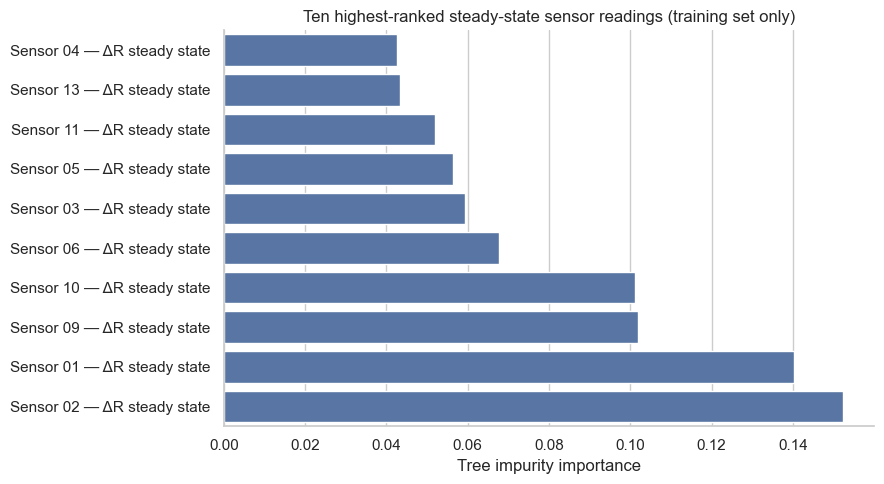

In [9]:
top_features = importance.head(10).sort_values("importance")
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=top_features,
    x="importance",
    y="feature",
    color=sns.color_palette("deep")[0],
    ax=ax,
)
ax.set(
    title="Ten highest-ranked steady-state sensor readings (training set only)",
    xlabel="Tree impurity importance",
    ylabel="",
)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

Before PCA, plot the two selected sensor readings. We standardize these two axes so their scales are comparable. The plot is colored by gas identity; the labels are added for interpretation, not to construct these coordinates.

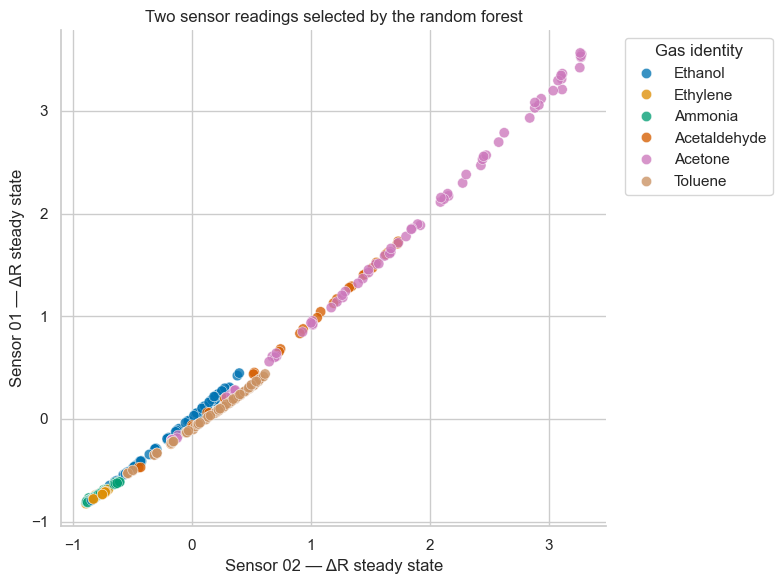

In [10]:
raw_pair_scaler = StandardScaler().fit(X_train[:, top_two_indices])
raw_pair_all = raw_pair_scaler.transform(X[:, top_two_indices])

raw_plot = pd.DataFrame(
    {
        "x": raw_pair_all[:, 0],
        "y": raw_pair_all[:, 1],
        "gas": pd.Series(y).map(GAS_NAMES).to_numpy(),
    }
)

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    data=raw_plot,
    x="x",
    y="y",
    hue="gas",
    hue_order=GAS_ORDER,
    palette=GAS_PALETTE,
    s=55,
    alpha=0.78,
    edgecolor="white",
    linewidth=0.4,
    ax=ax,
)
ax.set(
    title="Two sensor readings selected by the random forest",
    xlabel=top_two_features[0],
    ylabel=top_two_features[1],
)
ax.legend(title="Gas identity", bbox_to_anchor=(1.02, 1), loc="upper left")
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

The sensor readings may contain overlapping information. The heatmap below shows the Pearson correlation between each pair of the 16 readings, using the training data. Values close to 1 or −1 indicate a strong linear relationship; values close to 0 indicate a weak linear relationship.

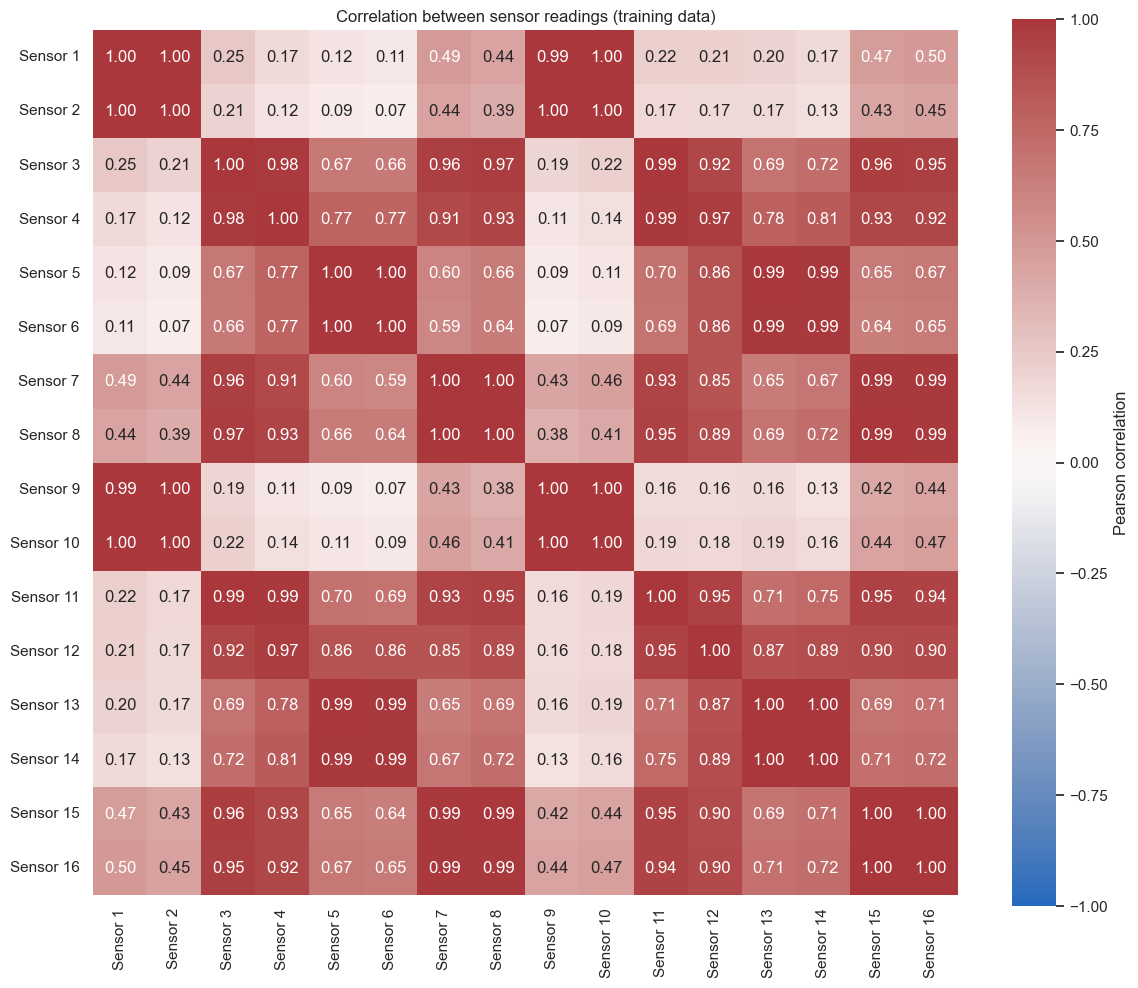

In [11]:
sensor_labels = [f"Sensor {i}" for i in range(1, 17)]
train_sensors = pd.DataFrame(X_train, columns=sensor_labels)
correlation = train_sensors.corr()

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    correlation,
    vmin=-1, vmax=1, center=0, cmap="vlag",
    annot=True, fmt=".2f", square=True,
    cbar_kws={"label": "Pearson correlation"},
    ax=ax,
)
ax.set_title("Correlation between sensor readings (training data)")
fig.tight_layout()
plt.show()

## 5. Fit PCA on the 16 sensor readings

PCA looks for directions that capture variation across the **whole 16-sensor matrix**. Sensor responses have different scales, so we standardize each feature using the training set's mean and standard deviation. Then PCA is fitted to the standardized training observations, without labels.

We keep the first four components so we can compare models using the first 2, 3, and 4 PCs.

In [12]:
feature_scaler = StandardScaler().fit(X_train)
X_train_scaled = feature_scaler.transform(X_train)
X_test_scaled = feature_scaler.transform(X_test)
X_all_scaled = feature_scaler.transform(X)

pca = PCA(n_components=4, random_state=RANDOM_STATE)
PC_train = pca.fit_transform(X_train_scaled)
PC_test = pca.transform(X_test_scaled)
PC_all = pca.transform(X_all_scaled)

variance_table = pd.DataFrame(
    {
        "component": [f"PC{i}" for i in range(1, 5)],
        "variance explained": pca.explained_variance_ratio_,
        "cumulative variance": np.cumsum(pca.explained_variance_ratio_),
    }
)
variance_display = variance_table.copy()
for column in ["variance explained", "cumulative variance"]:
    variance_display[column] = variance_display[column].map("{:.1%}".format)
display(variance_display)

,component,variance explained,cumulative variance
0,PC1,67.0%,67.0%
1,PC2,23.9%,91.0%
2,PC3,8.4%,99.3%
3,PC4,0.4%,99.8%


The next plot shows how much variation each of the first four directions explains. The principal components are combinations of the 16 sensor readings; no gas labels were used to compute them.

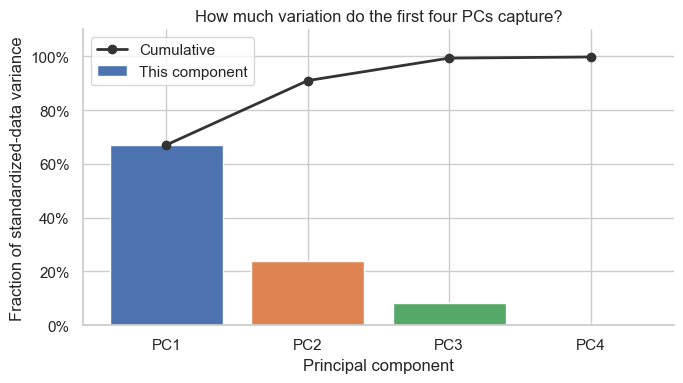

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
component_labels = variance_table["component"]
ax.bar(
    component_labels,
    variance_table["variance explained"],
    color=sns.color_palette("deep")[:4],
    label="This component",
)
ax.plot(
    component_labels,
    variance_table["cumulative variance"],
    color="#333333",
    marker="o",
    linewidth=2,
    label="Cumulative",
)
ax.set(
    title="How much variation do the first four PCs capture?",
    xlabel="Principal component",
    ylabel="Fraction of standardized-data variance",
    ylim=(0, 1.1),
)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend()
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

## 6. Can the principal components help a classifier?

We compare random forest models with the same settings, trained on different sets of features:

- all 16 original sensor readings;
- the first 2 PCs;
- the first 3 PCs;
- the first 4 PCs.

We use the random forest already trained on all 16 readings as our baseline. For the PCA models, the scaler and PCA are fitted using training data only. We compare **test accuracy**: the fraction of test samples classified correctly.

In [14]:
# Reuse the random forest trained on all 16 sensor readings.
predictions = {"All 16 sensor readings": feature_ranker.predict(X_test)}

# Train a random forest with the same settings for each set of PCs.
for n_components in (2, 3, 4):
    model = RandomForestClassifier(**forest_options)
    model.fit(PC_train[:, :n_components], y_train)
    predictions[f"First {n_components} PCs"] = model.predict(PC_test[:, :n_components])

score_rows = []
for name, prediction in predictions.items():
    score_rows.append(
        {
            "representation": name,
            "test accuracy": accuracy_score(y_test, prediction),
        }
    )

scores = pd.DataFrame(score_rows)
scores_display = scores.copy()
scores_display["test accuracy"] = scores_display["test accuracy"].map("{:.1%}".format)
display(scores_display)

,representation,test accuracy
0,All 16 sensor readings,90.3%
1,First 2 PCs,88.8%
2,First 3 PCs,91.8%
3,First 4 PCs,95.5%


## 7. Compare the two views

The accuracy table tells us how well the models classify the gases, but it does not show how the measurements for different gases are arranged. What patterns can we see in two original sensor readings, and what changes when we use the first two principal components?

A side-by-side scatterplot lets us compare these two views directly. Each point represents one gas exposure, and its color shows the known gas type.

The left panel uses the two sensor readings selected by the random forest. The right panel projects all 16 standardized sensor readings onto PC1 and PC2. Both plots have two axes, but the PCA plot uses information from all 16 sensors. The scaling and PCA directions were fit on training data only; both train and test observations are shown.

The gas labels are used only for the colors in these scatterplots. PCA does not know which dot is ethanol, ammonia, or any other class.

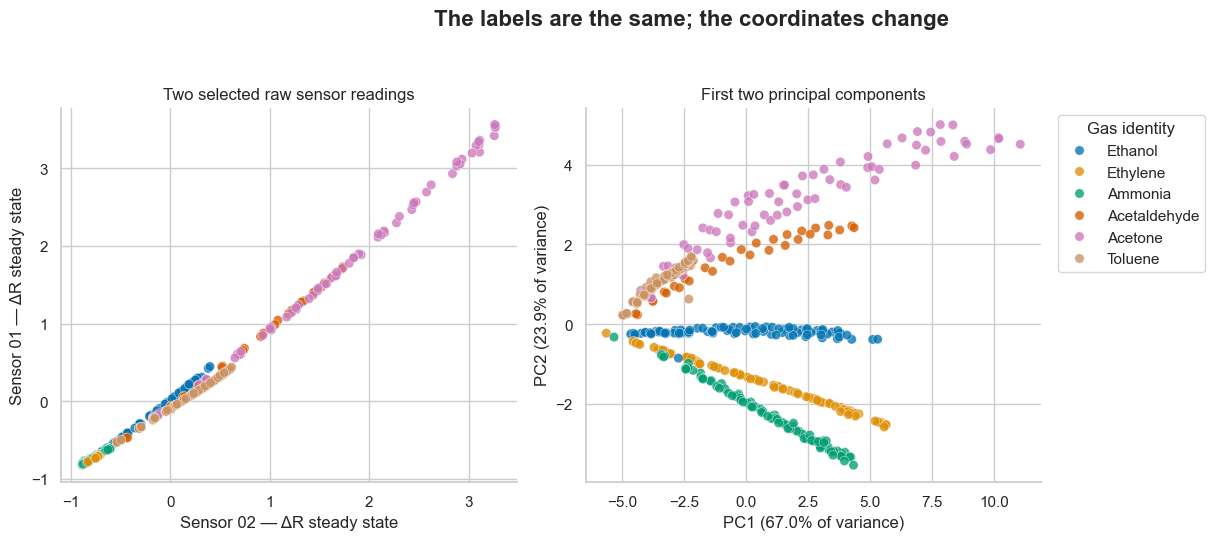

In [15]:
money_plot = pd.DataFrame(
    {
        "raw_x": raw_pair_all[:, 0],
        "raw_y": raw_pair_all[:, 1],
        "PC1": PC_all[:, 0],
        "PC2": PC_all[:, 1],
        "gas": pd.Series(y).map(GAS_NAMES).to_numpy(),
    }
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.scatterplot(
    data=money_plot,
    x="raw_x",
    y="raw_y",
    hue="gas",
    hue_order=GAS_ORDER,
    palette=GAS_PALETTE,
    s=46,
    alpha=0.78,
    edgecolor="white",
    linewidth=0.35,
    legend=False,
    ax=axes[0],
)
axes[0].set(
    title="Two selected raw sensor readings",
    xlabel=top_two_features[0],
    ylabel=top_two_features[1],
)

sns.scatterplot(
    data=money_plot,
    x="PC1",
    y="PC2",
    hue="gas",
    hue_order=GAS_ORDER,
    palette=GAS_PALETTE,
    s=46,
    alpha=0.78,
    edgecolor="white",
    linewidth=0.35,
    ax=axes[1],
)
axes[1].set(
    title="First two principal components",
    xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)",
    ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)",
)
axes[1].legend(title="Gas identity", bbox_to_anchor=(1.02, 1), loc="upper left")

fig.suptitle(
    "The labels are the same; the coordinates change",
    fontsize=16,
    fontweight="bold",
)
sns.despine()
fig.tight_layout(rect=(0, 0, 0.88, 0.94))
plt.show()

The gas classes overlap in the two-sensor view. In the PCA view, several classes form more distinct groups—even though PCA was fitted without using the gas labels.

## Takeaways

- Each observation has 128 features; this notebook uses one steady-state reading from each of the 16 sensors for the comparison.
- A pair of individually useful original measurements does not necessarily provide a useful 2D map.
- PCA combines information across many correlated features into new directions.
- In this example, a random forest using three or four PCs performs well compared with one using all 16 readings. PCA was fitted without the gas labels.
- After viewing the map, clustering can be introduced as the next question: can an algorithm recover groups without being told the gas identities?

> **A note on accuracy:** The gases do not have the same number of test samples, so ordinary accuracy gives more weight to gases with more samples. Balanced accuracy first measures accuracy for each gas, then averages those values, giving each gas equal weight. Here are the balanced accuracies for the same predictions:


In [16]:
balanced_scores = pd.DataFrame([
    {"features": name, "balanced test accuracy": balanced_accuracy_score(y_test, prediction)}
    for name, prediction in predictions.items()
])
balanced_scores_display = balanced_scores.copy()
balanced_scores_display["balanced test accuracy"] = balanced_scores_display["balanced test accuracy"].map("{:.1%}".format)
display(balanced_scores_display)

,features,balanced test accuracy
0,All 16 sensor readings,85.2%
1,First 2 PCs,87.1%
2,First 3 PCs,88.8%
3,First 4 PCs,95.8%


**Source:** Alexander Vergara, [Gas Sensor Array Drift Dataset](https://doi.org/10.24432/C5RP6W), UCI Machine Learning Repository. The dataset is provided under CC BY 4.0; cite the repository record when reusing it.

[← Return to Unsupervised learning](index.qmd)